# Figure 1 — Hamming and Euclidean distances between images

The code below reproduces the four images in Figure 1 and calculates the
distances shown under the three modified images. The top-left panel is the
20 × 20 reference image. Each pixel is represented both by a symbolic
colour class (red, green or blue) and by an RGB triplet with integer
components from 0 to 255.

The **Hamming distance** counts how many of the 400 corresponding pixels
belong to different colour classes. The **mean Euclidean distance**
calculates the Euclidean distance between the RGB triplets at each pixel
and averages those distances over all 400 pixels.

Both palette shifts preserve every pixel's colour class, so their
Hamming distances are zero. Their mean Euclidean distances reflect the
different magnitudes of the RGB changes. The cyclic reassignment changes
the class at every pixel, giving a Hamming distance of 400.

The choice of distance determines which differences the analysis
captures. The paper uses Hamming distance for the binary cellular
automata that follow, where the cell states are categorical.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Base palette (like NES vibe)
PALETTE_BASE = {
    0: (10, 10, 100),      # deep navy background
    1: (80, 200, 120),    # body green
    2: (240, 100, 80),   # eye red
}

# Slightly jittered colours (subtle lighting change)
PALETTE_JITTER = {
    0: (12, 12, 98),
    1: (85, 205, 122),
    2: (238, 142, 82),
}

# Large Hue change
PALETTE_LARGE = {
    0: (0, 0, 200),
    1: (10, 220, 50),
    2: (100, 12, 20),
}

# Rotated Colours
PALETTE_ROTATED = {
    0: (240, 100, 80),   
    1: (10, 10, 100),    
    2: (80, 200, 120),   
}

GRID_BASE = [
    [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,1,1,0,0,1,1,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,1,1,1,1,1,1,1,1,0,0,0,0,0,0],
    [0,0,0,0,0,1,1,2,1,1,1,1,2,1,1,0,0,0,0,0],
    [0,0,0,0,1,1,1,1,1,2,2,1,1,1,1,1,0,0,0,0],
    [0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0],
    [0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0],
    [0,0,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,0,0],
    [0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,0,0],
    [0,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0],
    [0,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,0,0],
    [0,0,1,1,1,0,1,1,0,1,1,0,1,1,0,1,1,1,0,0],
    [0,0,1,1,0,1,1,1,1,0,0,1,1,1,1,0,1,1,0,0],
    [0,0,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,0,0],
    [0,0,0,1,1,1,1,1,1,0,0,1,1,1,1,1,1,0,0,0],
    [0,0,0,0,1,1,1,0,0,0,0,0,1,1,1,0,0,0,0,0],
    [0,0,0,0,0,1,1,0,0,0,0,0,1,1,0,0,0,0,0,0],
    [0,0,0,0,0,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,1,1,0,0,1,1,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],
]

def palette_to_rgb(grid, palette):
    h, w = len(grid), len(grid[0])
    img = np.zeros((h, w, 3), dtype=np.uint8)
    for i in range(h):
        for j in range(w):
            img[i, j] = palette[grid[i][j]]
    return img

# Render images
images = {}
images['img_base']   = [palette_to_rgb(GRID_BASE, PALETTE_BASE), 'Base Image']
images['img_jitter'] = [palette_to_rgb(GRID_BASE, PALETTE_JITTER), 'Small Colour Shift']        
images['img_large'] = [palette_to_rgb(GRID_BASE, PALETTE_LARGE), 'Large Colour Shift']        
images['img_rot']     = [palette_to_rgb(GRID_BASE, PALETTE_ROTATED), 'RGB Colour Rotation']

In [3]:
# Distances
def hamming_on_indices(A, B):
    A = np.array(A); B = np.array(B)
    assert A.shape == B.shape
    mismatches = (A != B).sum()
    return mismatches

def hamming_on_rgb(A, B):
    # exact RGB equality per pixel
    eq = np.all(A == B, axis=-1)
    return (~eq).sum()

def euclidean_rgb(A, B):
    # sum of L2 distances across pixels
    diff = A.astype(np.float32) - B.astype(np.float32)
    per_pix = np.sqrt((diff**2).sum(axis=-1))
    return per_pix.sum(), per_pix.mean()

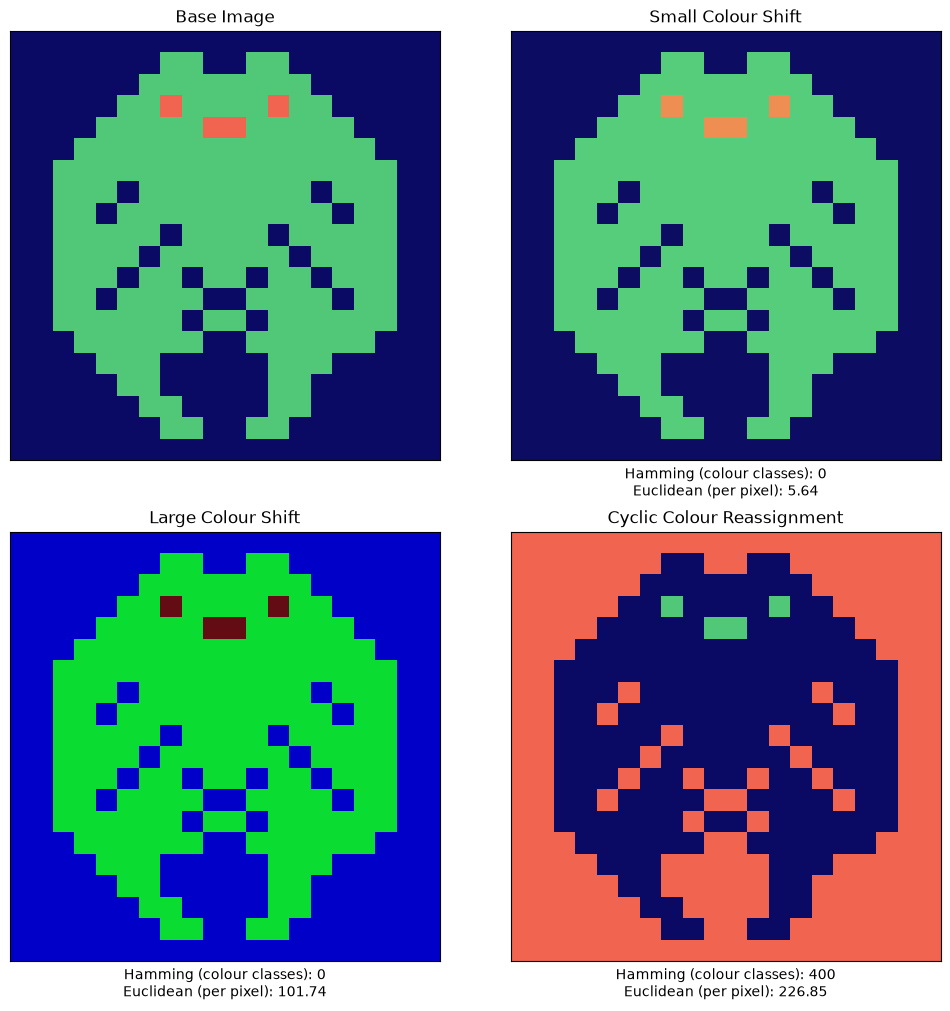

In [4]:
base_classes = np.asarray(GRID_BASE)
rotated_classes = (base_classes + 2) % 3
reference = palette_to_rgb(base_classes, PALETTE_BASE)

variants = (
    ("Base Image", base_classes, PALETTE_BASE),
    ("Small Colour Shift", base_classes, PALETTE_JITTER),
    ("Large Colour Shift", base_classes, PALETTE_LARGE),
    ("Cyclic Colour Reassignment", rotated_classes, PALETTE_BASE),
)

fig, axes = plt.subplots(2, 2, figsize=(10, 10), layout="constrained")

for ax, (title, classes, palette) in zip(axes.flat, variants):
    image = palette_to_rgb(classes, palette)
    ax.imshow(image, interpolation="nearest")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

    if title != "Base Image":
        hamming = np.count_nonzero(classes != base_classes)
        rgb_difference = image.astype(float) - reference.astype(float)
        mean_euclidean = np.linalg.norm(rgb_difference, axis=-1).mean()
        ax.set_xlabel(
            f"Hamming (colour classes): {hamming}\n"
            f"Euclidean (per pixel): {mean_euclidean:.2f}"
        )

plt.show()